# Lecture 2 examples: finite probability spaces and counting

This notebook accompanies the blackboard lecture. It emphasizes four distinctions:

1. a finite sample space need not carry a uniform law;
2. replacement changes the sample space and probability law;
3. exact enumeration and Monte Carlo simulation answer different computational questions;
4. every counting probability depends on a stated random mechanism.

All simulations use an explicit NumPy generator and a fixed seed.

In [25]:
import itertools
import math

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import numpy as np

SEED = 202602
rng = np.random.default_rng(SEED)

plt.style.use("seaborn-v0_8-whitegrid")
COURSE_BLUE = "#2f6690"
COURSE_ORANGE = "#d97a2b"
COURSE_GREEN = "#3a8d6d"
COURSE_RED = "#b5443c"
COURSE_PURPLE = "#7656a5"

print(f"NumPy version: {np.__version__}")
print(f"Reproducibility seed: {SEED}")

NumPy version: 1.26.4
Reproducibility seed: 202602


## Example 1: four-digit PINs

For integers $0\leq k\leq N$, the **falling factorial** is

$$
N^{\underline{k}}:=N(N-1)\cdots(N-k+1)=\frac{N!}{(N-k)!},\qquad N^{\underline 0}:=1.
$$

It counts ordered selections of $k$ distinct objects from $N$ objects. Assume every ordered PIN in $\Omega=\{0,1,\ldots,9\}^4$ is equally likely. For the event $A$ that all four digits are distinct,

$$
|\Omega|=10^4,\qquad |A|=10^{\underline 4}=10\cdot9\cdot8\cdot7.
$$

We first enumerate exactly, then estimate the same model probability by simulation.

In [43]:
digits = range(10)
pins = list(itertools.product(digits, repeat=4)) # Read https://docs.python.org/3/library/itertools.html 
distinct_pins = [pin for pin in pins if len(set(pin)) == 4]

count_formula = math.perm(10, 4) # Choose 4 from 10 without repetition
probability_exact = count_formula / 10**4

assert len(pins) == 10**4
assert len(distinct_pins) == count_formula

print(f"All PINs:                 {len(pins)}")
print(f"PINs with distinct digits: {len(distinct_pins)}")
print(f"Exact probability:         {probability_exact:.4f}")
print(f"Repeated-digit probability: {1 - probability_exact:.4f}")

All PINs:                 10000
PINs with distinct digits: 5040
Exact probability:         0.5040
Repeated-digit probability: 0.4960


Exact probability:        0.50400
Monte Carlo estimate:     0.50703
Absolute simulation error: 0.00303


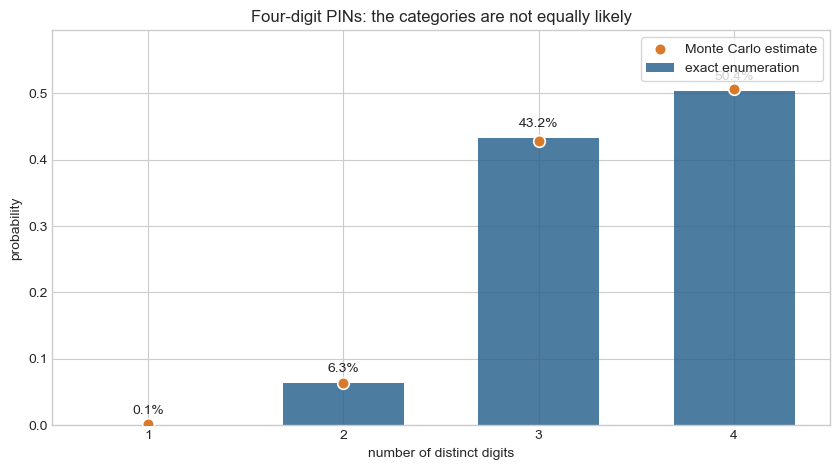

In [45]:
n_simulations = 100_000
simulated_pins = rng.integers(0, 10, size=(n_simulations, 4))
sorted_pins = np.sort(simulated_pins, axis=1)
all_distinct = np.all(np.diff(sorted_pins, axis=1) != 0, axis=1)
probability_mc = all_distinct.mean()

print(f"Exact probability:        {probability_exact:.5f}")
print(f"Monte Carlo estimate:     {probability_mc:.5f}")
print(f"Absolute simulation error: {abs(probability_mc - probability_exact):.5f}")

distinct_levels = np.arange(1, 5)
exact_distinct_probabilities = np.array([
    sum(len(set(pin)) == level for pin in pins) / len(pins)
    for level in distinct_levels
])
simulated_n_distinct = 1 + np.sum(np.diff(sorted_pins, axis=1) != 0, axis=1)
mc_distinct_probabilities = np.array([
    np.mean(simulated_n_distinct == level)
    for level in distinct_levels
])

assert np.isclose(exact_distinct_probabilities.sum(), 1)
assert np.isclose(mc_distinct_probabilities.sum(), 1)

fig, ax = plt.subplots(figsize=(8.5, 4.8))
bars = ax.bar(
    distinct_levels,
    exact_distinct_probabilities,
    width=0.62,
    color=COURSE_BLUE,
    alpha=0.86,
    label="exact enumeration",
)
ax.scatter(
    distinct_levels,
    mc_distinct_probabilities,
    s=70,
    color=COURSE_ORANGE,
    edgecolor="white",
    linewidth=1.2,
    zorder=3,
    label="Monte Carlo estimate",
)
for bar, probability in zip(bars, exact_distinct_probabilities):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        probability + 0.012,
        f"{probability:.1%}",
        ha="center",
        va="bottom",
        fontsize=10,
    )
ax.set(
    title="Four-digit PINs: the categories are not equally likely",
    xlabel="number of distinct digits",
    ylabel="probability",
    xticks=distinct_levels,
    ylim=(0, exact_distinct_probabilities.max() * 1.18),
)
ax.legend(frameon=True)
fig.tight_layout()
plt.show()

## Example 2: two urn experiments as probability spaces

Let $U=U_{\mathrm R}\cup U_{\mathrm B}$ contain five labeled red and seven labeled blue balls. We record four ordered draws.

- With replacement: $\Omega_{\mathrm{rep}}=U^4$, $\mathcal F_{\mathrm{rep}}=2^{\Omega_{\mathrm{rep}}}$, and every tuple has mass $12^{-4}$.
- Without replacement: $\Omega_{\mathrm{nrep}}$ contains the distinct-entry tuples in $U^4$, $\mathcal F_{\mathrm{nrep}}=2^{\Omega_{\mathrm{nrep}}}$, and every tuple has mass $(12^{\underline 4})^{-1}$.

### Visualizing the first two draws

A $12\times12$ grid makes the change in sample space concrete. Each square is an ordered pair of labeled balls. Without replacement, the diagonal is removed because the same labeled ball cannot be drawn twice.

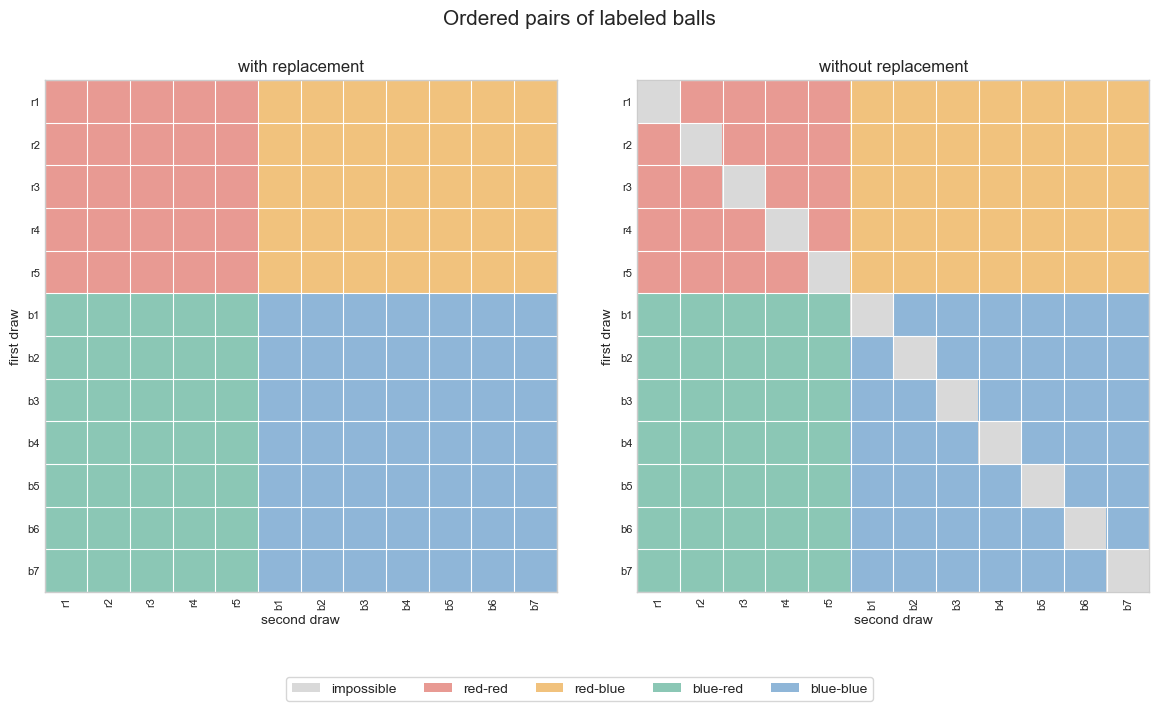

In [7]:
ball_labels = [f"r{i}" for i in range(1, 6)] + [f"b{i}" for i in range(1, 8)]
pair_categories = np.empty((12, 12), dtype=int)

for first in range(12):
    for second in range(12):
        first_is_red = first < 5
        second_is_red = second < 5
        if first_is_red and second_is_red:
            pair_categories[first, second] = 1  # red-red
        elif first_is_red and not second_is_red:
            pair_categories[first, second] = 2  # red-blue
        elif not first_is_red and second_is_red:
            pair_categories[first, second] = 3  # blue-red
        else:
            pair_categories[first, second] = 4  # blue-blue

pair_categories_nrep = pair_categories.copy()
np.fill_diagonal(pair_categories_nrep, 0)

pair_cmap = ListedColormap([
    "#d9d9d9",
    "#e89a93",
    "#f1c27d",
    "#8bc7b5",
    "#8fb6d8",
])
pair_legend = [
    Patch(facecolor="#d9d9d9", label="impossible"),
    Patch(facecolor="#e89a93", label="red-red"),
    Patch(facecolor="#f1c27d", label="red-blue"),
    Patch(facecolor="#8bc7b5", label="blue-red"),
    Patch(facecolor="#8fb6d8", label="blue-blue"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 7.2))
for ax, grid, title in zip(
    axes,
    (pair_categories, pair_categories_nrep),
    ("with replacement", "without replacement"),
):
    ax.imshow(grid, cmap=pair_cmap, vmin=0, vmax=4, interpolation="none")
    ax.set(
        title=title,
        xlabel="second draw",
        ylabel="first draw",
        xticks=np.arange(12),
        yticks=np.arange(12),
    )
    ax.set_xticklabels(ball_labels, rotation=90, fontsize=8)
    ax.set_yticklabels(ball_labels, fontsize=8)
    ax.grid(False)
    ax.set_xticks(np.arange(-0.5, 12, 1), minor=True)
    ax.set_yticks(np.arange(-0.5, 12, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8)
    ax.tick_params(which="minor", bottom=False, left=False)

fig.suptitle("Ordered pairs of labeled balls", fontsize=15)
fig.legend(handles=pair_legend, loc="lower center", bbox_to_anchor=(0.5, 0.01), ncol=5, frameon=True)
fig.tight_layout(rect=(0, 0.15, 1, 0.95))
plt.show()

### Exact enumeration and the full red-count distribution

Let $A_{\mathrm{rep}}$ denote the event that exactly two of the four draws are red in the replacement model. Its favorable outcomes are counted by three choices:

- $\binom42$: choose which two ordered draw positions are red;
- $5^2$: choose one of five labeled red balls at each red position;
- $7^2$: choose one of seven labeled blue balls at each blue position.

Replacement makes the label choices independent and allows the same ball to appear twice. Thus

$$
|A_{\mathrm{rep}}|=\binom42\cdot5^2\cdot7^2,\qquad \mathbb P_{\mathrm{rep}}(A_{\mathrm{rep}})=\binom42\left(\frac5{12}\right)^2\left(\frac7{12}\right)^2.
$$

Without replacement, the event depends only on the selected set. Every four-ball subset has exactly $4!$ orderings, so forgetting order produces a uniform law on four-element subsets. Of the $\binom{12}{4}$ possible subsets, exactly $\binom52\binom72$ contain two red and two blue balls. Thus

$$
\mathbb P_{\mathrm{nrep}}(A_{\mathrm{nrep}})=\frac{\binom52\binom72}{\binom{12}{4}}.
$$

Exact enumeration constructs both sample spaces literally. The grouped bars compare the complete probability laws of the number of red draws, while the overlaid points show Monte Carlo estimates from the same two experiments.

With replacement: favorable-count factors
  red positions: 6
  red labels:    25 = 5^2
  blue labels:   49 = 7^2
  product:       7350

Without replacement: unordered-subset count
  favorable subsets: 210 = C(5,2) C(7,2)
  total subsets:     495 = C(12,4)

Exact |Omega_rep|:          20736
Exact |Omega_nrep|:         11880
Exact P_rep(two red):       0.35446
Exact P_nrep(two red):      0.42424


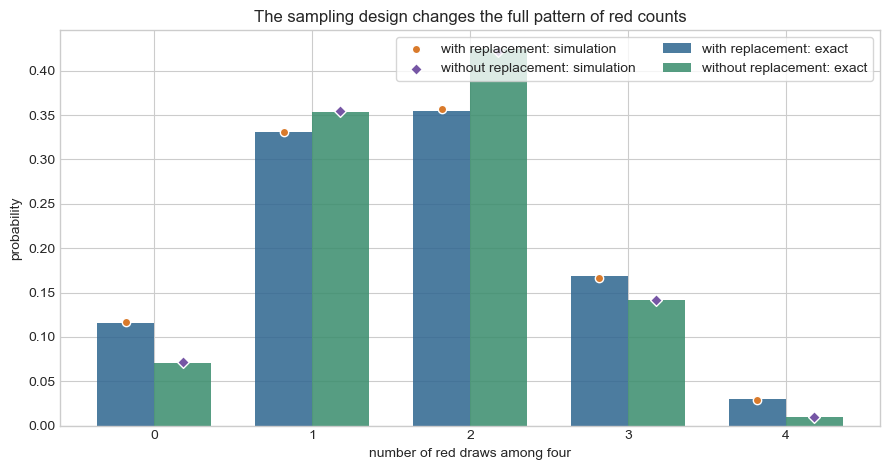

In [9]:
red_balls = tuple(f"r_{i}" for i in range(1, 6))
blue_balls = tuple(f"b_{i}" for i in range(1, 8))
balls = red_balls + blue_balls
red_ball_set = set(red_balls)

omega_rep = list(itertools.product(balls, repeat=4))
omega_nrep = list(itertools.permutations(balls, 4))

event_rep = [draw for draw in omega_rep if sum(ball in red_ball_set for ball in draw) == 2]
event_nrep = [draw for draw in omega_nrep if sum(ball in red_ball_set for ball in draw) == 2]

probability_rep = len(event_rep) / len(omega_rep)
probability_nrep = len(event_nrep) / len(omega_nrep)
# Multiplication principle: positions, red labels, then blue labels.
red_position_choices = math.comb(4, 2)
red_label_choices_rep = 5**2
blue_label_choices_rep = 7**2
favorable_subsets_nrep = math.comb(5, 2) * math.comb(7, 2)
total_subsets_nrep = math.comb(12, 4)
formula_rep = red_position_choices * red_label_choices_rep * blue_label_choices_rep / 12**4
formula_nrep = favorable_subsets_nrep / total_subsets_nrep

assert len(omega_rep) == 12**4
assert len(omega_nrep) == math.perm(12, 4)
assert np.isclose(probability_rep, formula_rep)
assert np.isclose(probability_nrep, formula_nrep)

print("With replacement: favorable-count factors")
print(f"  red positions: {red_position_choices}")
print(f"  red labels:    {red_label_choices_rep} = 5^2")
print(f"  blue labels:   {blue_label_choices_rep} = 7^2")
print(f"  product:       {red_position_choices * red_label_choices_rep * blue_label_choices_rep}")
print()
print("Without replacement: unordered-subset count")
print(f"  favorable subsets: {favorable_subsets_nrep} = C(5,2) C(7,2)")
print(f"  total subsets:     {total_subsets_nrep} = C(12,4)")
print()
print(f"Exact |Omega_rep|:          {len(omega_rep):5d}")
print(f"Exact |Omega_nrep|:         {len(omega_nrep):5d}")
print(f"Exact P_rep(two red):       {probability_rep:.5f}")
print(f"Exact P_nrep(two red):      {probability_nrep:.5f}")

red_count_values = np.arange(5)
exact_red_probabilities_rep = np.array([
    sum(sum(ball in red_ball_set for ball in draw) == count for draw in omega_rep) / len(omega_rep)
    for count in red_count_values
])
exact_red_probabilities_nrep = np.array([
    sum(sum(ball in red_ball_set for ball in draw) == count for draw in omega_nrep) / len(omega_nrep)
    for count in red_count_values
])

n_urn_simulations = 50_000
simulated_rep_labels = rng.integers(0, 12, size=(n_urn_simulations, 4))
simulated_nrep_labels = np.argpartition(
    rng.random((n_urn_simulations, 12)), kth=3, axis=1
)[:, :4]
simulated_red_counts_rep = np.sum(simulated_rep_labels < 5, axis=1)
simulated_red_counts_nrep = np.sum(simulated_nrep_labels < 5, axis=1)
mc_red_probabilities_rep = np.bincount(simulated_red_counts_rep, minlength=5) / n_urn_simulations
mc_red_probabilities_nrep = np.bincount(simulated_red_counts_nrep, minlength=5) / n_urn_simulations

width = 0.36
fig, ax = plt.subplots(figsize=(9, 4.8))
ax.bar(
    red_count_values - width / 2,
    exact_red_probabilities_rep,
    width,
    color=COURSE_BLUE,
    alpha=0.86,
    label="with replacement: exact",
)
ax.bar(
    red_count_values + width / 2,
    exact_red_probabilities_nrep,
    width,
    color=COURSE_GREEN,
    alpha=0.86,
    label="without replacement: exact",
)
ax.scatter(
    red_count_values - width / 2,
    mc_red_probabilities_rep,
    marker="o",
    color=COURSE_ORANGE,
    edgecolor="white",
    zorder=3,
    label="with replacement: simulation",
)
ax.scatter(
    red_count_values + width / 2,
    mc_red_probabilities_nrep,
    marker="D",
    color=COURSE_PURPLE,
    edgecolor="white",
    zorder=3,
    label="without replacement: simulation",
)
ax.set(
    title="The sampling design changes the full pattern of red counts",
    xlabel="number of red draws among four",
    ylabel="probability",
    xticks=red_count_values,
)
ax.legend(ncol=2, frameon=True)
fig.tight_layout()
plt.show()

## Example 3: ordered and unordered representations

For $N=5$ labeled objects and $k=3$ draws, the three spaces used in the notes have cardinalities $N^k$, $N^{\underline k}$, and $\binom Nk$. We also check why discarding order after sampling with replacement does **not** produce a uniform law on multisets.

Ordered, with replacement:    125
Ordered, without replacement:  60
Unordered, no replacement:     10

Ordered representations after order is discarded:
(1, 1, 1): 1  -> probability 0.008
(1, 2, 3): 6  -> probability 0.048


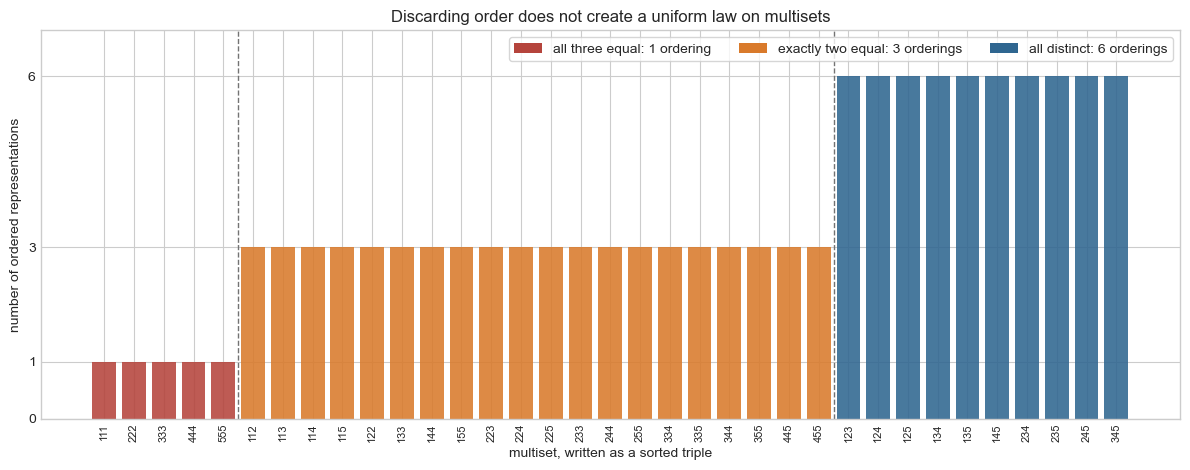

In [11]:
objects = tuple(range(1, 6))
k = 3

ordered_rep = list(itertools.product(objects, repeat=k))
ordered_nrep = list(itertools.permutations(objects, k))
unordered_nrep = list(itertools.combinations(objects, k))

assert len(ordered_rep) == 5**3
assert len(ordered_nrep) == math.perm(5, 3)
assert len(unordered_nrep) == math.comb(5, 3)

print(f"Ordered, with replacement:    {len(ordered_rep):3d}")
print(f"Ordered, without replacement: {len(ordered_nrep):3d}")
print(f"Unordered, no replacement:    {len(unordered_nrep):3d}")

representation_count = {}
for draw in ordered_rep:
    multiset = tuple(sorted(draw))
    representation_count[multiset] = representation_count.get(multiset, 0) + 1

constant_multiset = (1, 1, 1)
distinct_multiset = (1, 2, 3)
print("\nOrdered representations after order is discarded:")
print(f"{constant_multiset}: {representation_count[constant_multiset]}  -> probability {representation_count[constant_multiset] / 5**3:.3f}")
print(f"{distinct_multiset}: {representation_count[distinct_multiset]}  -> probability {representation_count[distinct_multiset] / 5**3:.3f}")

multiset_items = sorted(representation_count.items(), key=lambda item: (item[1], item[0]))
multiset_labels = ["".join(map(str, multiset)) for multiset, _ in multiset_items]
multiplicities = np.array([count for _, count in multiset_items])
multiplicity_colors = {
    1: COURSE_RED,
    3: COURSE_ORANGE,
    6: COURSE_BLUE,
}
bar_colors = [multiplicity_colors[count] for count in multiplicities]

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.bar(np.arange(len(multiset_items)), multiplicities, color=bar_colors, alpha=0.88)
ax.axvline(4.5, color="0.45", lw=1, ls="--")
ax.axvline(24.5, color="0.45", lw=1, ls="--")
ax.set(
    title="Discarding order does not create a uniform law on multisets",
    xlabel="multiset, written as a sorted triple",
    ylabel="number of ordered representations",
    xticks=np.arange(len(multiset_items)),
    yticks=[0, 1, 3, 6],
    ylim=(0, 6.8),
)
ax.set_xticklabels(multiset_labels, rotation=90, fontsize=8)
ax.legend(
    handles=[
        Patch(facecolor=COURSE_RED, label="all three equal: 1 ordering"),
        Patch(facecolor=COURSE_ORANGE, label="exactly two equal: 3 orderings"),
        Patch(facecolor=COURSE_BLUE, label="all distinct: 6 orderings"),
    ],
    ncol=3,
    frameon=True,
)
fig.tight_layout()
plt.show()

## Example 4: inclusion-exclusion

Choose uniformly from $\Omega=\{1,\ldots,100\}$. We count integers divisible by 2, 3, or 5 and verify the three-set inclusion-exclusion identity exactly.

Direct union count:             74
Inclusion-exclusion count:      74
Uniform-model probability:      0.74


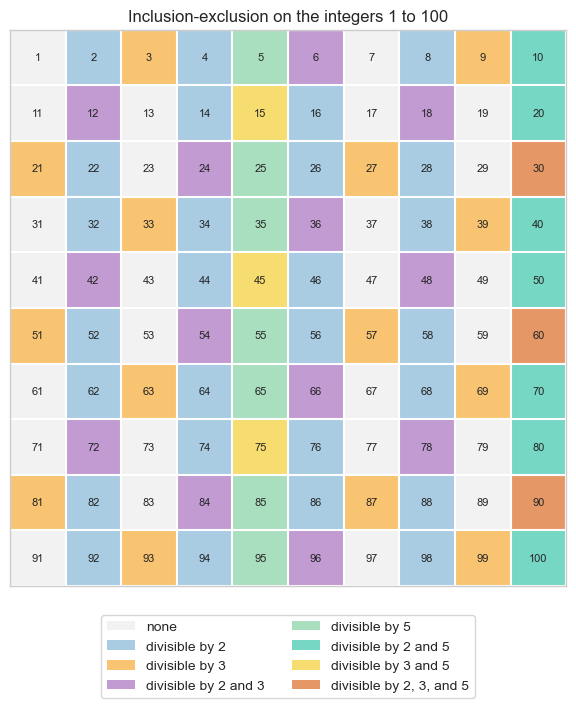

In [13]:
omega = set(range(1, 101))
A_2 = {value for value in omega if value % 2 == 0}
A_3 = {value for value in omega if value % 3 == 0}
A_5 = {value for value in omega if value % 5 == 0}

union_count = len(A_2 | A_3 | A_5)
inclusion_exclusion_count = (
    len(A_2) + len(A_3) + len(A_5)
    - len(A_2 & A_3) - len(A_2 & A_5) - len(A_3 & A_5)
    + len(A_2 & A_3 & A_5)
)

assert union_count == inclusion_exclusion_count == 74
print(f"Direct union count:             {union_count}")
print(f"Inclusion-exclusion count:      {inclusion_exclusion_count}")
print(f"Uniform-model probability:      {union_count / len(omega):.2f}")

integer_grid = np.arange(1, 101).reshape(10, 10)
membership_mask = (
    (integer_grid % 2 == 0).astype(int)
    + 2 * (integer_grid % 3 == 0).astype(int)
    + 4 * (integer_grid % 5 == 0).astype(int)
)
membership_colors = [
    "#f2f2f2",
    "#a9cce3",
    "#f8c471",
    "#c39bd3",
    "#a9dfbf",
    "#76d7c4",
    "#f7dc6f",
    "#e59866",
]
membership_labels = [
    "none",
    "divisible by 2",
    "divisible by 3",
    "divisible by 2 and 3",
    "divisible by 5",
    "divisible by 2 and 5",
    "divisible by 3 and 5",
    "divisible by 2, 3, and 5",
]

fig, ax = plt.subplots(figsize=(9, 8.2))
ax.imshow(
    membership_mask,
    cmap=ListedColormap(membership_colors),
    vmin=0,
    vmax=7,
    interpolation="none",
)
for row in range(10):
    for column in range(10):
        ax.text(column, row, str(integer_grid[row, column]), ha="center", va="center", fontsize=8)

ax.set_title("Inclusion-exclusion on the integers 1 to 100")
ax.set_xticks([])
ax.set_yticks([])
ax.grid(False)
ax.set_xticks(np.arange(-0.5, 10, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 10, 1), minor=True)
ax.grid(which="minor", color="white", linewidth=1.5)
ax.tick_params(which="minor", bottom=False, left=False)
ax.legend(
    handles=[Patch(facecolor=color, label=label) for color, label in zip(membership_colors, membership_labels)],
    loc="upper center",
    bbox_to_anchor=(0.5, -0.04),
    ncol=2,
    frameon=True,
)
fig.tight_layout(rect=(0, 0.12, 1, 1))
plt.show()

## Example 5: the birthday problem

Under the stated uniform model, the exact collision probability for $1\leq n\leq365$ people is

$$
1-\frac{365^{\underline n}}{365^n}.
$$

For $n>365$, the collision probability is one. The exact curve is compared with Monte Carlo estimates at selected group sizes.

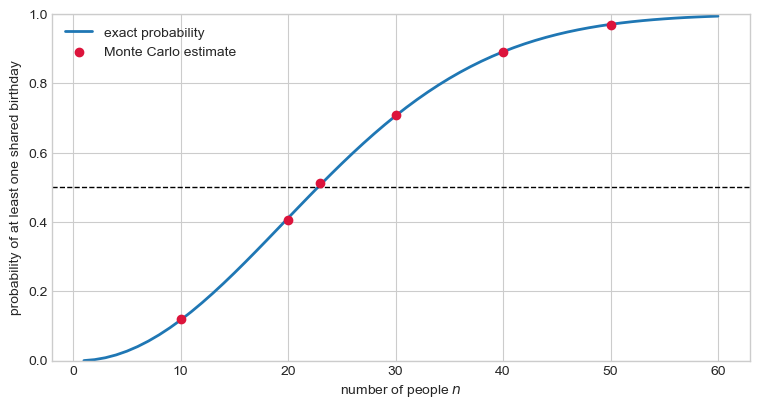

n=10: exact=0.1169, simulation=0.1201, error=0.0031
n=20: exact=0.4114, simulation=0.4065, error=0.0049
n=23: exact=0.5073, simulation=0.5122, error=0.0049
n=30: exact=0.7063, simulation=0.7078, error=0.0015
n=40: exact=0.8912, simulation=0.8919, error=0.0006
n=50: exact=0.9704, simulation=0.9696, error=0.0008


In [15]:
def birthday_collision_probability(n, n_days=365):
    if n > n_days:
        return 1.0
    no_collision = math.prod(n_days - k for k in range(n)) / n_days**n
    return 1.0 - no_collision

def simulate_birthday_collision(n, n_simulations=20_000, n_days=365):
    birthdays = rng.integers(0, n_days, size=(n_simulations, n))
    ordered = np.sort(birthdays, axis=1)
    collision = np.any(np.diff(ordered, axis=1) == 0, axis=1)
    return collision.mean()

group_sizes = np.arange(1, 61)
exact_curve = np.array([birthday_collision_probability(int(n)) for n in group_sizes])
checkpoint_sizes = np.array([10, 20, 23, 30, 40, 50])
simulation_estimates = np.array([simulate_birthday_collision(int(n)) for n in checkpoint_sizes])

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(group_sizes, exact_curve, lw=2, label="exact probability")
ax.scatter(checkpoint_sizes, simulation_estimates, color="crimson", zorder=3, label="Monte Carlo estimate")
ax.axhline(0.5, color="black", ls="--", lw=1)
ax.set(xlabel="number of people $n$", ylabel="probability of at least one shared birthday", ylim=(0, 1))
ax.legend()
plt.show()

for n, estimate in zip(checkpoint_sizes, simulation_estimates):
    exact = birthday_collision_probability(int(n))
    print(f"n={n:2d}: exact={exact:.4f}, simulation={estimate:.4f}, error={abs(estimate - exact):.4f}")

## Exercises

*Presentation format:* Define the objects and assumptions, show the intermediate argument or computation, and finish with a clear conclusion. For the Python/data task, bring one informative figure and explain what it demonstrates.

1. **Conceptual:** A program first chooses a subset size uniformly from $\{0,1,\ldots,10\}$, then chooses uniformly among subsets of that size. For a fixed subset $S$ with $|S|=k$, derive its selection probability. Compare $k=0,1,5$ with $2^{-10}$, compare the induced size distributions, and propose a correct uniform-subset algorithm.
2. **Mathematical:**

   1. An eight-character identifier is generated uniformly from 26 uppercase letters, 26 lowercase letters, and 10 digits, with replacement. How many identifiers contain at least one character from each category? State the corresponding probability and justify the inclusion-exclusion terms.

   2. Let $A_1,\ldots,A_M\subseteq\Omega$. Prove the pointwise identity
      $$
      \mathbf 1_{\bigcup_{s=1}^M A_s}(\omega)
      =
      \sum_{\emptyset\neq J\subseteq\{1,\ldots,M\}}
      (-1)^{|J|+1}\mathbf 1_{\bigcap_{s\in J}A_s}(\omega).
      $$
      *Hint.* If $\omega$ belongs to exactly $h$ of the events, show that the right-hand side equals $\sum_{k=1}^h(-1)^{k+1}\binom hk=1$. Deduce the general inclusion-exclusion formulas for cardinalities and probabilities.

3. **Python/data:** A data set has 15 labeled rows, four of which are flagged. A five-row test set is selected uniformly without replacement. Use `itertools.combinations` to enumerate all test sets and compute the exact probability that at least two flagged rows are selected. Verify the result with a combinatorial formula and with Monte Carlo simulation.

4. **Urn probabilities:** An urn contains four red, three blue, and two green balls, all individually labeled. Three balls are drawn without replacement, with every ordered triple of distinct ball labels equally likely.

   1. Specify the probability space $(\Omega_{\mathrm{nrep}},\mathcal F_{\mathrm{nrep}},\mathbb P_{\mathrm{nrep}})$. Justify why the events below can also be counted using uniformly distributed three-element subsets of ball labels.
   2. Compute the probabilities that exactly two drawn balls are red and one is blue; that all three have the same color; and that at least one is green. Give exact fractions and justify each counting formula. Use a complement for the last event.
   3. Compute the probability that all three colors appear. Then repeat this calculation for sampling with replacement, where every ordered triple of ball labels is equally likely. Specify the new probability space $(\Omega_{\mathrm{rep}},\mathcal F_{\mathrm{rep}},\mathbb P_{\mathrm{rep}})$ and explain the difference between the two probabilities.